Приводя уравнение $g(x) = 0$ к виду, для которого справедлив принцип сжимающих отображений, найти корни уравнения с точностью $\varepsilon = 10^{-4}$. Составить алгоритм и написать программный код, реализующий метод последовательных приближений, предусматривающий:
* построение графика $g(x)$;
* вычисление априорной оценки количества итераций;
* вывод на печать последней итерации и ее номера.
$$2x + \cos x + \frac{2x}{1 + x^2} = 0$$


In [14]:
import numpy as np
import matplotlib.pyplot as plt

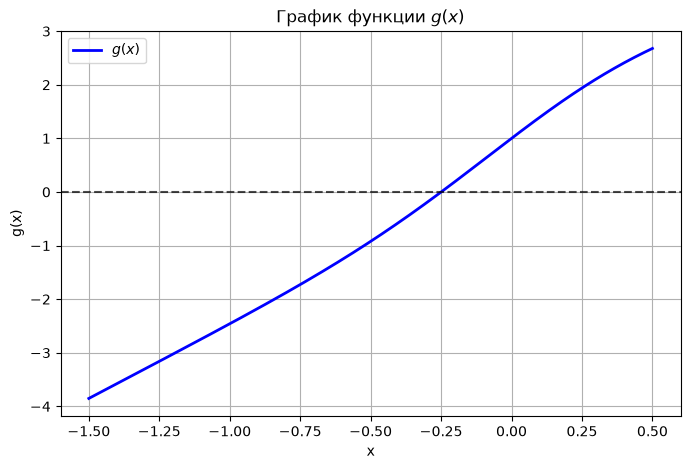

альфа: 0.16959
текущий x: -0.24945
итерация 5
после итерации: -0.24959
апостериорная оценка ||xn - x*|| <= 2.7e-05


In [15]:
def g(x):
    return 2*x + np.cos(x) + 2*x / (1+ x**2)

a = -1
b = 0
k1 = 2.84
k2 = 4.0

lambda_ = 2 / (k1 + k2)
alpha = (k2 - k1) / (k1 + k2)

def f(x):
    return x - lambda_ * g(x)

x0 = 0.0
x1 = f(x0)
e = 1e-4
n = int(np.log(e * (1 - alpha) / abs(x1 - x0)) / np.log(alpha)) + 1
x_curr = x0

for i in range(1, n):
    x_next = f(x_curr)
    x_curr = x_next

x_vals = np.linspace(-1.5, 0.5, 400)
y_vals = g(x_vals)
plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_vals, label='$g(x)$', color='blue', lw=2)
plt.axhline(0, color='black', linestyle='--', alpha=0.7)
plt.title('График функции $g(x)$')
plt.xlabel('x')
plt.ylabel('g(x)')
plt.grid(True)
plt.legend()
plt.show()
print(f"альфа: {alpha:.5f}")
print(f"текущий x: {x_curr:.5f}")
x = f(x_curr)
print(f"итерация {n}")
print(f"после итерации: {x:.5f}")
print(f"апостериорная оценка ||xn - x*|| <= {(alpha / (1 - alpha)) * np.abs(x - x_curr):.1e}")

alphaC  = 0.5000
alphaL2 = 0.2789


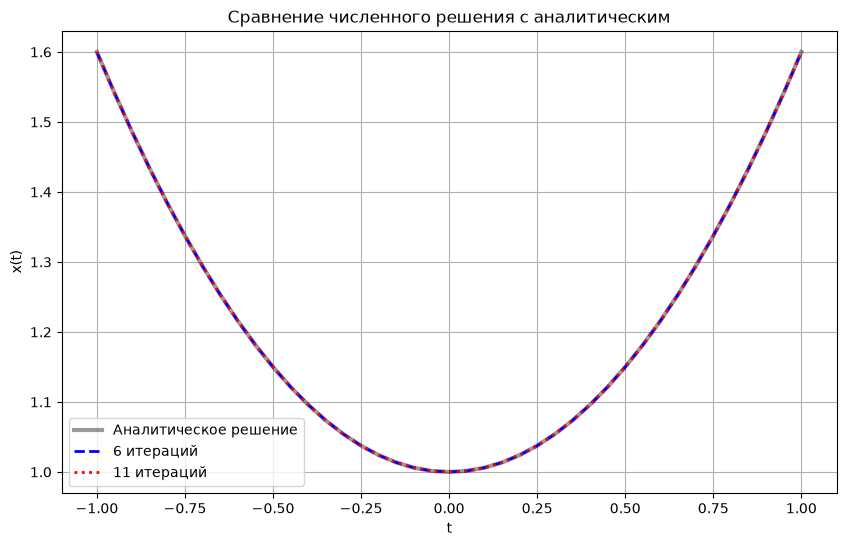

Апостериорная оценка в C (11 итераций):  3.9e-04
Апостериорная оценка в L2 (6 итераций): 1.2e-08


In [16]:
def calculate_integral(a, b, f, step=0.05):
    n = int(round((b - a) / step))
    if n % 2 != 0:
        n += 1
    h = (b - a) / n
    
    sum1 = 0
    for i in range(1, n, 2):
        x1 = a + i * h 
        sum1 += f(x1)
        
    sum2 = 0
    for i in range(2, n, 2):
        x2 = a + i * h 
        sum2 += f(x2)
        
    return (h/3) * (f(a) + 4*sum1 + 2*sum2 + f(b))

lambda_ = 0.25

def get_alphaC(step_t=0.05, step_integr=0.05):
    max_integral = 0.0
    t_points = np.arange(-1, 1 + step_t/2, step_t)
    
    for t in t_points:
        f_s = lambda s: abs(t * s + t**2)
        
        current_integral = calculate_integral(-1, 1, f_s, step=step_integr)
        if current_integral > max_integral:
            max_integral = current_integral
            
    alpha = abs(lambda_) * max_integral
    return alpha

def get_alphaL2(step_integr=0.05):
    def out_function(t):
        in_function = lambda s: (t * s + t**2)**2
        return calculate_integral(-1, 1, in_function, step=step_integr)
        
    double_integral = calculate_integral(-1, 1, out_function, step=step_integr)
    alpha = abs(lambda_) * np.sqrt(double_integral)
    return alpha

alphaC = get_alphaC()
alphaL2 = get_alphaL2()
print(f"alphaC  = {alphaC:.4f}")
print(f"alphaL2 = {alphaL2:.4f}") 

def solve(iterations, step=0.02):
    t_vals = np.arange(-1, 1 + step/2, step)
    x_current = np.zeros_like(t_vals)
    x_prev = np.zeros_like(t_vals)
    
    for _ in range(iterations):
        x_prev = np.copy(x_current)
        x_next = np.zeros_like(t_vals)
        
        for i, t in enumerate(t_vals):
            def integrand(s):
                x_s = np.interp(s, t_vals, x_current)
                return (t * s + t**2) * x_s
            
            integr_val = calculate_integral(-1, 1, integrand, step=step)
            x_next[i] = 1 + lambda_ * integr_val
            
        x_current = x_next
        
    return t_vals, x_current, x_prev

step = 0.05
x0 = 0
x1 = 1
eps = 1e-3
n_itersC = int(np.log(eps * (1 - alphaC) / (abs(x0 - x1))) / np.log(alphaC)) + 1
norm_for_n = np.sqrt(calculate_integral(-1, 1, lambda s: 1, step=step)) 
n_itersL2 = int(np.log(eps * (1 - alphaL2) / norm_for_n) / np.log(alphaL2)) + 1
t_vals, x_6, x_5 = solve(iterations=n_itersC, step=step)
_, x_11, x_10 = solve(iterations=n_itersL2, step=step)

x_analytical = 1 + 0.6 * t_vals**2

plt.figure(figsize=(10, 6))
plt.plot(t_vals, x_analytical, label='Аналитическое решение', color='black', linewidth=3, alpha = 0.4)
plt.plot(t_vals, x_6, label=f"{n_itersL2} итераций", color='blue', linestyle='--', linewidth=2)
plt.plot(t_vals, x_11, label=f"{n_itersC} итераций", color='red', linestyle=':', linewidth=2)

plt.title('Сравнение численного решения с аналитическим')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.legend()
plt.grid(True)
plt.show()     

norm_C = np.max(np.abs(x_10 - x_11))
error_C = (alphaC / (1 - alphaC)) * norm_C
print(f"Апостериорная оценка в C ({n_itersC} итераций):  {error_C:.1e}")

def diff_squared(t):
    return np.interp(t, t_vals, (x_5 - x_6)**2)
norm_L2 = np.sqrt(calculate_integral(-1, 1, diff_squared, step=step))
error_L2 = (alphaL2 / (1 - alphaL2)) * norm_L2
print(f"Апостериорная оценка в L2 ({n_itersL2} итераций): {error_L2:.1e}")
